# R7 · Gene-list queries on every section (Fig 4C)

On each of the 8 indexed sections and seeds 0–4, each curated tissue signature, as a template query, is searched with
Spindle-naive (exact d_B^S, top 10) and Spindle (its first 10). Readouts: Cliff's δ of the tile score, co-variation lift
on S and the overlap of Spindle's tiles with Spindle-naive's.

The rules are fixed in `experiments/common/queries.py`.

* **Prerequisites:** `R0_index_cache.ipynb`.
* **Writes:** `results/queries/`:
  * `per_dataset/<key>/seed<s>_gene_lists.csv`
  * `lists.csv` (summary over seeds)
* **Skips** every (dataset, seed) whose CSV exists (`FORCE = True` redoes all).
* **Runtime / memory:** under 1 h in total on one core; peak about 6 GB (brain_cancer: 817k cells × 480 genes, counts and
  log-expression in float32).

In [1]:
import gc
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "datasets.yaml").exists())
sys.path.insert(0, str(ROOT / "experiments" / "common"))
import matplotlib.pyplot as plt
import pandas as pd

import data
import queries as qx
import results_io as rio
import sections as sx

FORCE = False
TOPIC = "queries"
print(data.stamp())

{'tag': 'method-v2', 'describe': 'method-v3-dirty', 'commit': 'b35f7d4'}


## Queries, one (dataset, seed) at a time

In [2]:
for key in data.indexed_keys():
    for seed in data.SEEDS:
        f = f"per_dataset/{key}/seed{seed}_gene_lists.csv"
        if not FORCE and (rio.topic(TOPIC) / f).exists():
            print(f"{key} seed {seed}: exists, skipped")
            continue
        S = sx.load(key, seed, parts=qx.PARTS)
        G = qx.gene_lists(S, seed)
        rio.write_csv(G, TOPIC, f, "every tissue signature x method (naive_partial, spindle_partial): delta, "
                      "co-variation, Jaccard")
        del S, G
        gc.collect()
        print(f"  peak memory so far {rio.peak_rss_gb():.1f} GB", flush=True)

skin_melanoma seed 0: exists, skipped
skin_melanoma seed 1: exists, skipped
skin_melanoma seed 2: exists, skipped
skin_melanoma seed 3: exists, skipped
skin_melanoma seed 4: exists, skipped
kidney_nondiseased seed 0: exists, skipped
kidney_nondiseased seed 1: exists, skipped
kidney_nondiseased seed 2: exists, skipped
kidney_nondiseased seed 3: exists, skipped
kidney_nondiseased seed 4: exists, skipped
breast_cancer seed 0: exists, skipped
breast_cancer seed 1: exists, skipped
breast_cancer seed 2: exists, skipped
breast_cancer seed 3: exists, skipped
breast_cancer seed 4: exists, skipped
lung_cancer seed 0: exists, skipped
lung_cancer seed 1: exists, skipped
lung_cancer seed 2: exists, skipped
lung_cancer seed 3: exists, skipped
lung_cancer seed 4: exists, skipped
pancreatic_cancer seed 0: exists, skipped
pancreatic_cancer seed 1: exists, skipped
pancreatic_cancer seed 2: exists, skipped
pancreatic_cancer seed 3: exists, skipped
pancreatic_cancer seed 4: exists, skipped
lymph_node seed

## Summaries over seeds

In [3]:
lists = qx.summary_lists(pd.concat([pd.read_csv(rio.topic(TOPIC) / f"per_dataset/{k}/seed{s}_gene_lists.csv")
                                    for k in data.indexed_keys() for s in data.SEEDS], ignore_index=True))
rio.write_csv(lists, TOPIC, "lists.csv", "per dataset, list and method: mean and s.d. over seeds")

wrote results/queries/lists.csv: 48 rows


PosixPath('/home/NAShome/ghoss18/spindle_dev/results/queries/lists.csv')

In [4]:
lists.pivot_table(index=["key", "list"], columns="method", values=["delta", "lift"], sort=False).round(3)

delta                  \
method                                        naive_partial spindle_partial   
key                list                                                       
skin_melanoma      Melanocyte_Tumor                   0.874           0.815   
                   Keratinocyte_Epidermis             0.783           0.786   
                   Immune_Infiltrate                  0.819           0.878   
kidney_nondiseased Tubular_Epithelium                 0.675           0.653   
                   Injury_Immune_Infiltrate           0.566           0.278   
breast_cancer      Luminal_Tumor_Core                 0.729           0.642   
                   Macrophage_Myeloid                 0.546           0.741   
                   Basal_Myoepithelial                0.803           0.813   
                   Endothelial_Vascular               0.920           0.685   
                   Proliferation_Signature            0.739           0.687   
lung_cancer        Alveolar_Airway_Epithelium         0.368           0.434   
                   Vascular_Endothelial               0.821           0.706   
pancreatic_cancer  Exocrine_Ductal                    0.557           0.566   
                   Endocrine_Islet                    0.775           0.766   
                   Mast_Cell_Stroma                   0.834           0.867   
lymph_node         B_Cell_Germinal_Center             0.514           0.510   
                   T_Cell_Zone                        0.657           0.677   
                   Macrophage_DC_Niche                0.714           0.704   
                   Lymphatic_Vascular_Stroma          0.861           0.934   
lymph_node_5k      B_Cell_Germinal_Center             0.767           0.754   
                   T_Cell_Zone                        0.677           0.688   
brain_cancer       Glioma_Tumor_Proliferative         0.330           0.349   
                   Microglia_Myeloid                  0.417           0.552   
                   TIL_Lymphocyte                     0.068           0.182   

                                                       lift                  
method                                        naive_partial spindle_partial  
key                list                                                      
skin_melanoma      Melanocyte_Tumor                   0.076           0.135  
                   Keratinocyte_Epidermis             0.264           0.275  
                   Immune_Infiltrate                  0.016          -0.052  
kidney_nondiseased Tubular_Epithelium                -0.035          -0.033  
                   Injury_Immune_Infiltrate           0.024          -0.008  
breast_cancer      Luminal_Tumor_Core                 0.021           0.066  
                   Macrophage_Myeloid                 0.107           0.033  
                   Basal_Myoepithelial                0.432           0.393  
                   Endothelial_Vascular               0.079           0.168  
                   Proliferation_Signature            0.161           0.172  
lung_cancer        Alveolar_Airway_Epithelium         0.001          -0.014  
                   Vascular_Endothelial               0.298           0.166  
pancreatic_cancer  Exocrine_Ductal                    0.128           0.126  
                   Endocrine_Islet                    0.393           0.354  
                   Mast_Cell_Stroma                   0.062           0.046  
lymph_node         B_Cell_Germinal_Center             0.009           0.013  
                   T_Cell_Zone                        0.001          -0.037  
                   Macrophage_DC_Niche                0.061           0.071  
                   Lymphatic_Vascular_Stroma          0.055           0.083  
lymph_node_5k      B_Cell_Germinal_Center             0.011          -0.004  
                   T_Cell_Zone                       -0.050          -0.053  
brain_cancer       Glioma_Tumor_Proliferative   

## Quick look (not saved)

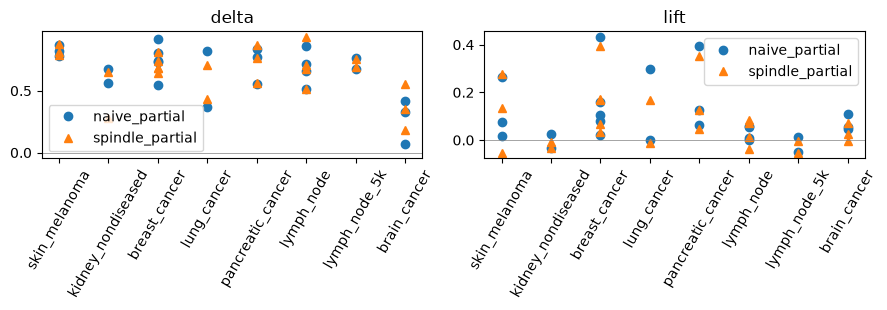

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
for a, col in zip(ax, ("delta", "lift")):
    for meth, mk in (("naive_partial", "o"), ("spindle_partial", "^")):
        v = lists[lists.method == meth]
        a.plot(v.key, v[col], mk, ls="", label=meth)
    a.axhline(0, color="grey", lw=0.5)
    a.set_title(col)
    a.tick_params(axis="x", rotation=60)
    a.legend()
plt.tight_layout()
plt.show()

In [6]:
rio.write_manifest(TOPIC, "R7_queries.ipynb", inputs=["results/_cache"],
                   notes="Fig 4C. Old names: gene-list query T/TS -> method naive_partial/spindle_partial, "
                         "jacc_T -> jacc_naive_partial.")

wrote results/queries/manifest.json: 41 files; peak memory 0.19 GB


{'topic': 'queries',
 'notebook': 'R7_queries.ipynb',
 'date': '2026-11-05 09:44',
 'tag': 'method-v2',
 'describe': 'method-v3-dirty',
 'commit': 'b35f7d4',
 'inputs': ['results/_cache'],
 'peak_rss_gb': 0.19,
 'notes': 'Fig 4C. Old names: gene-list query T/TS -> method naive_partial/spindle_partial, jacc_T -> jacc_naive_partial.',
 'files': {'lists.csv': {'description': 'per dataset, list and method: mean and s.d. over seeds',
   'rows': 48,
   'bytes': 13041},
  'per_dataset/brain_cancer/seed0_gene_lists.csv': {'description': 'every tissue signature x method (naive_partial, spindle_partial): delta, co-variation, Jaccard',
   'rows': 6,
   'bytes': 1164},
  'per_dataset/brain_cancer/seed1_gene_lists.csv': {'description': 'every tissue signature x method (naive_partial, spindle_partial): delta, co-variation, Jaccard',
   'rows': 6,
   'bytes': 1170},
  'per_dataset/brain_cancer/seed2_gene_lists.csv': {'description': 'every tissue signature x method (naive_partial, spindle_partial): de